In [1]:
import matplotlib.pyplot  as plt
import numpy as np
import pandas as pd
import os
df=pd.read_csv(r"C:\Users\user\Downloads\retail_sales_clean.csv")
display(df)



,date,year,month_num,month,store,category,units_sold,unit_price_rs,discount_pct,revenue_lakhs,customers,profit_margin_pct,marketing_spend_lakhs,customer_rating,return_rate_pct
0,2024-01-01,2024,1,Jan,Kozhikode,Electronics,42,17630,20,7.40,15,6.0,0.44,3.9,4.5
1,2024-01-01,2024,1,Jan,Kozhikode,Clothing,303,1220,20,3.70,108,21.4,0.12,4.2,7.2
2,2024-01-01,2024,1,Jan,Kozhikode,Grocery,1656,350,15,5.80,567,7.1,0.31,4.0,1.6
3,2024-01-01,2024,1,Jan,Kozhikode,Home,161,2520,10,4.06,59,18.6,0.12,4.3,4.4
4,2024-01-01,2024,1,Jan,Kochi,Electronics,45,17700,5,7.96,16,9.1,0.38,4.2,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,2025-12-01,2025,12,Dec,Kochi,Home,275,2490,25,6.85,81,16.6,0.12,4.7,4.0
284,2025-12-01,2025,12,Dec,Thiruvananthapuram,Electronics,60,17870,10,10.72,17,8.6,0.46,4.0,4.4
285,2025-12-01,2025,12,Dec,Thiruvananthapuram,Clothing,481,1180,5,5.68,158,24.0,0.35,4.0,8.6
286,2025-12-01,2025,12,Dec,Thiruvananthapuram,Grocery,2283,350,5,7.99,853,5.3,0.32,4.1,0.9


# Part 1 & 2

In [3]:
#1)
print("Shape:",df.shape)
print("Data type:",df.dtypes)
print(df.isnull(). sum())
print(df.duplicated().sum())

Shape: (288, 15)
Data type: date                      object
year                       int64
month_num                  int64
month                     object
store                     object
category                  object
units_sold                 int64
unit_price_rs              int64
discount_pct               int64
revenue_lakhs            float64
customers                  int64
profit_margin_pct        float64
marketing_spend_lakhs    float64
customer_rating          float64
return_rate_pct          float64
dtype: object
date                     0
year                     0
month_num                0
month                    0
store                    0
category                 0
units_sold               0
unit_price_rs            0
discount_pct             0
revenue_lakhs            0
customers                0
profit_margin_pct        0
marketing_spend_lakhs    0
customer_rating          0
return_rate_pct          0
dtype: int64
0


In [2]:
df25 = df[df['year']==2025]
display(df25.head())
print(df25.shape)


,date,year,month_num,month,store,category,units_sold,unit_price_rs,discount_pct,revenue_lakhs,customers,profit_margin_pct,marketing_spend_lakhs,customer_rating,return_rate_pct
144,2025-01-01,2025,1,Jan,Kozhikode,Electronics,51,18130,0,9.25,18,11.4,0.46,4.0,4.7
145,2025-01-01,2025,1,Jan,Kozhikode,Clothing,331,1200,5,3.97,115,19.3,0.12,3.5,8.2
146,2025-01-01,2025,1,Jan,Kozhikode,Grocery,1852,340,20,6.30,597,5.0,0.25,4.3,1.8
147,2025-01-01,2025,1,Jan,Kozhikode,Home,175,2380,10,4.17,57,15.0,0.12,4.3,3.0
148,2025-01-01,2025,1,Jan,Kochi,Electronics,52,18200,20,9.46,14,7.7,0.47,3.8,4.1


(144, 15)


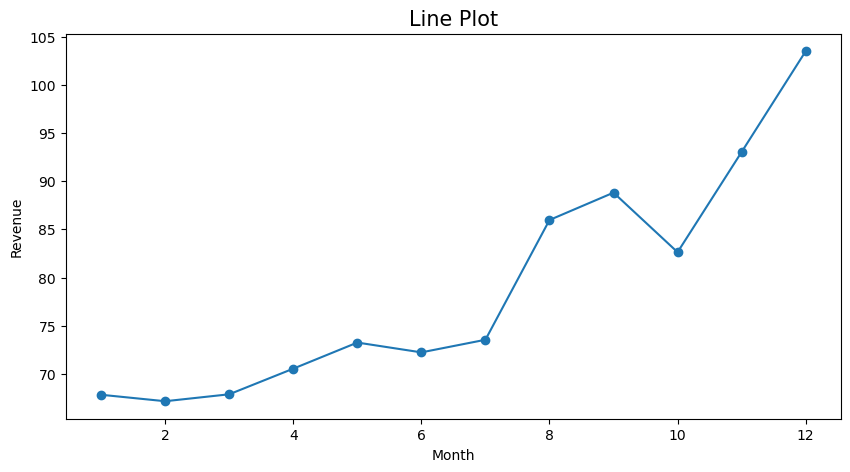

In [4]:
#2) Line plot

plt.figure(figsize=(10,5))
revenue_lakhs=df25.groupby("month_num")["revenue_lakhs"].sum()
plt.plot(revenue_lakhs.index,revenue_lakhs.values,marker="o")
plt.xlabel("Month")
plt.ylabel("Revenue")
#plt.xticks(range(1,13),["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sept","Oct","Nov","Dec"])
plt.title("Line Plot",fontsize=15)
plt.show()


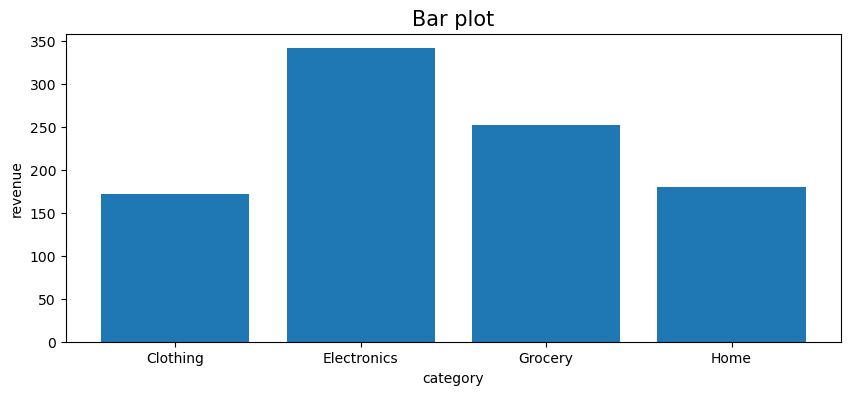

In [5]:
#3) Bar plot
category_revenue=df25.groupby("category")["revenue_lakhs"].sum()
plt.figure(figsize=(10,4))
plt.bar(category_revenue.index,category_revenue.values)
plt.xlabel("category")
plt.ylabel("revenue")
plt.title("Bar plot", fontsize=15)
plt.show()

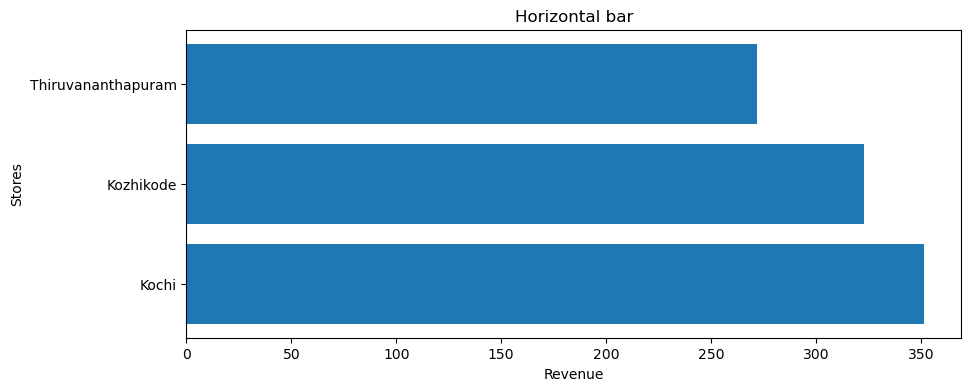

In [10]:
revenue_store=df25.groupby("store")["revenue_lakhs"].sum()
revenue_store=revenue_store.sort_values(ascending=False)
plt.figure(figsize=(10,4))
plt.barh(revenue_store.index,revenue_store.values)
plt.xlabel("Revenue")
plt.ylabel("Stores")
plt.title("Horizontal bar")
plt.show()

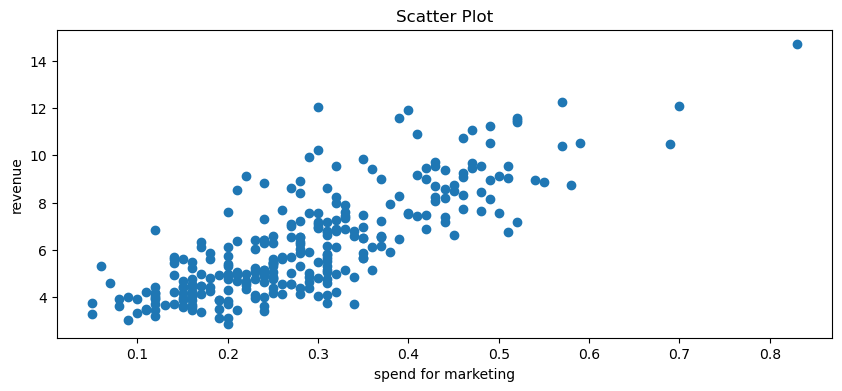

In [ ]:
#5) Scatter plt
plt.figure(figsize=(10,4))
plt.scatter(df["marketing_spend_lakhs"],df["revenue_lakhs"])
plt.title("Scatter Plot")
plt.xlabel("spend for marketing")
plt.ylabel("revenue")
plt.show()
#  strong positive relationship between marketing spending and revenue

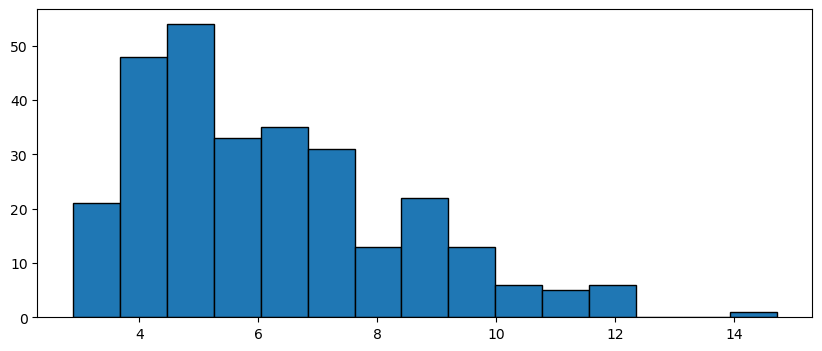

In [13]:
#6) Histogram
plt.figure(figsize=(10,4))
plt.hist(df["revenue_lakhs"],bins=15,edgecolor="black")
plt.show()

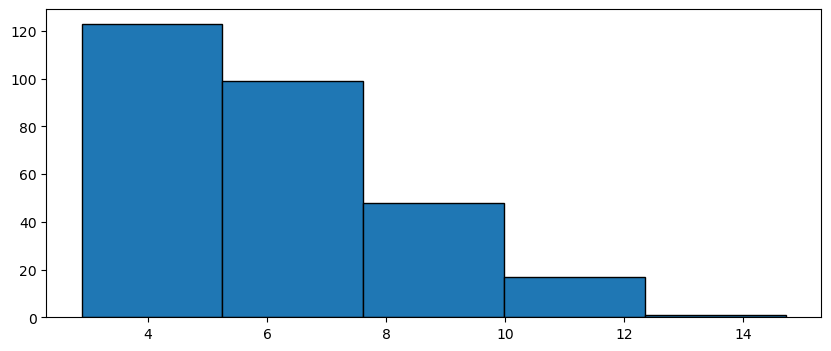

In [14]:
plt.figure(figsize=(10,4))
plt.hist(df["revenue_lakhs"],bins=5,edgecolor="black")
plt.show()

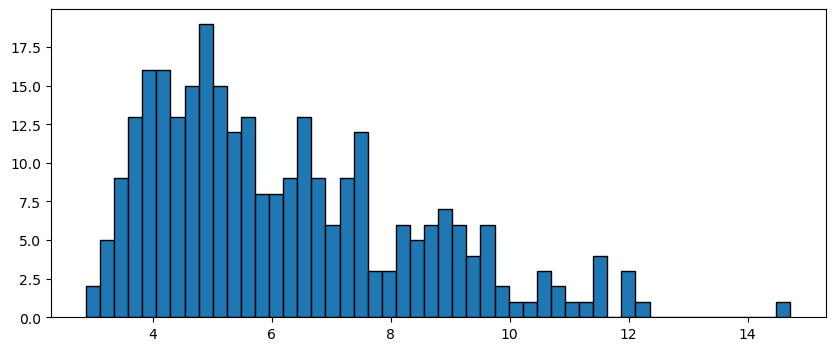

In [15]:
plt.figure(figsize=(10,4))
plt.hist(df["revenue_lakhs"],bins=50,edgecolor="black")
plt.show()

In [ ]:
# with 5 bins:bars are wider, with 15 bins: distribution becomes clearer and with 50 bins bars become narrower showing more variations in data

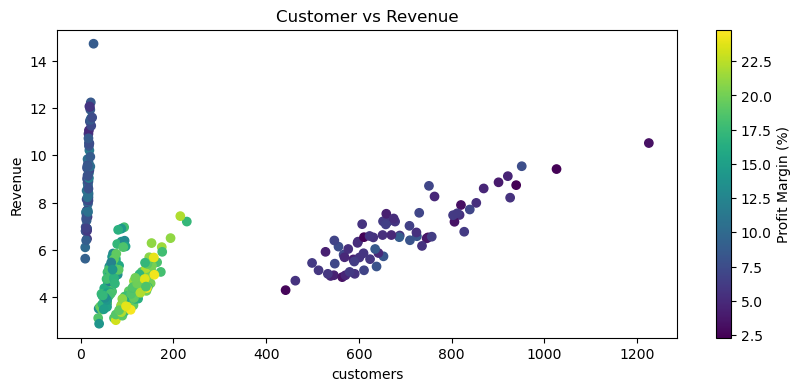

In [17]:
#7) scatter with size and color
plt.figure(figsize=(10,4))
plt.scatter(df["customers"],df["revenue_lakhs"],c=df["profit_margin_pct"])
plt.title("Customer vs Revenue")
plt.xlabel("customers")
plt.ylabel("Revenue")
plt.colorbar(label="Profit Margin (%)")
plt.show()

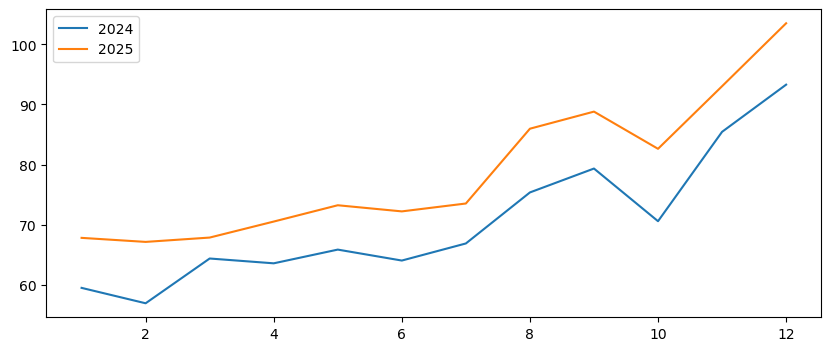

In [19]:
#8)Two lines and one chart
df24=df[df["year"]==2024]
plt.figure(figsize=(10,4))
plt.plot(df24.groupby("month_num")["revenue_lakhs"].sum(),label="2024")
plt.plot(df25.groupby("month_num")["revenue_lakhs"].sum(),label="2025")
plt.legend()
plt.show()


# part 3

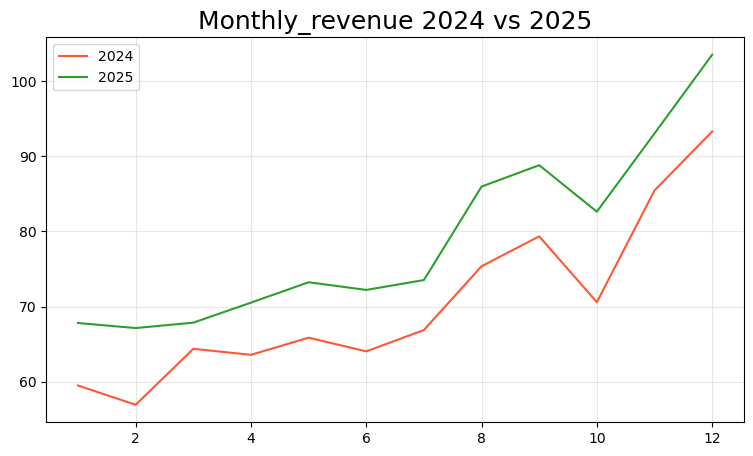

In [22]:
#9)
plt.figure(figsize=(9,5))
plt.plot(df24.groupby("month_num")["revenue_lakhs"].sum(),color="#ff5733",label="2024")
plt.plot(df25.groupby("month_num")["revenue_lakhs"].sum(),color="tab:green",label="2025")
plt.title("Monthly_revenue 2024 vs 2025",fontsize=18)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.show()

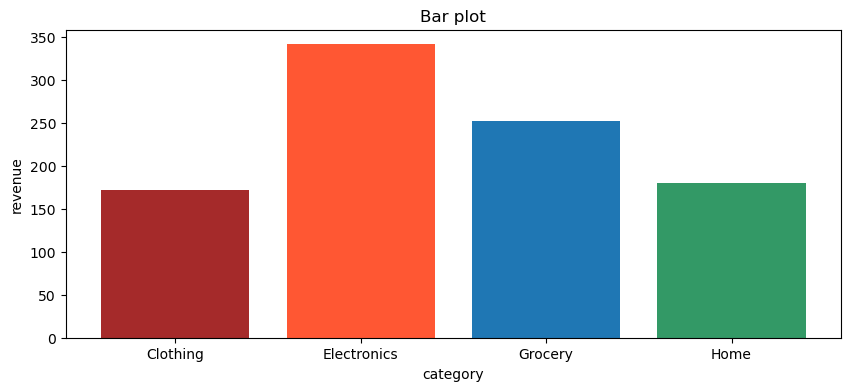

In [14]:
#10)
category_revenue=df25.groupby("category",as_index=False)["revenue_lakhs"].sum()
plt.figure(figsize=(10,4))
plt.bar(category_revenue["category"],category_revenue["revenue_lakhs"],color=["brown","#ff5733","tab:blue",(0.2,0.6,0.4)])
plt.xlabel("category")
plt.ylabel("revenue")
plt.title("Bar plot")
plt.show()

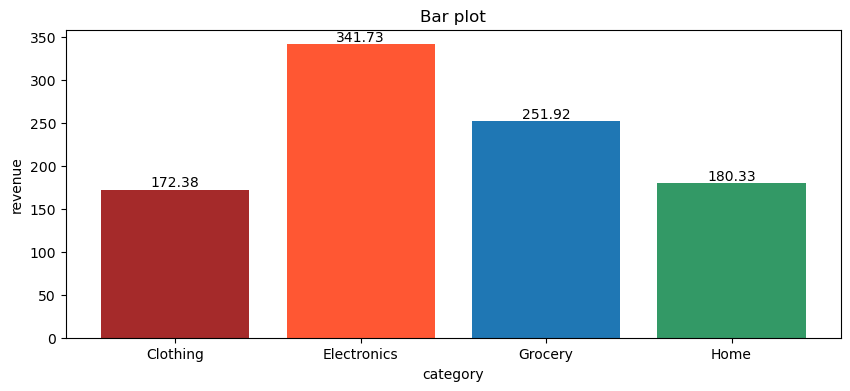

In [15]:
#11)
category_revenue=df25.groupby("category")["revenue_lakhs"].sum()
plt.figure(figsize=(10,4))
bars=plt.bar(category_revenue.index,category_revenue.values,color=["brown","#ff5733","tab:blue",(0.2,0.6,0.4)])
plt.bar_label(bars,fmt="%.2f")
plt.xlabel("category")
plt.ylabel("revenue")
plt.title("Bar plot")
plt.show()

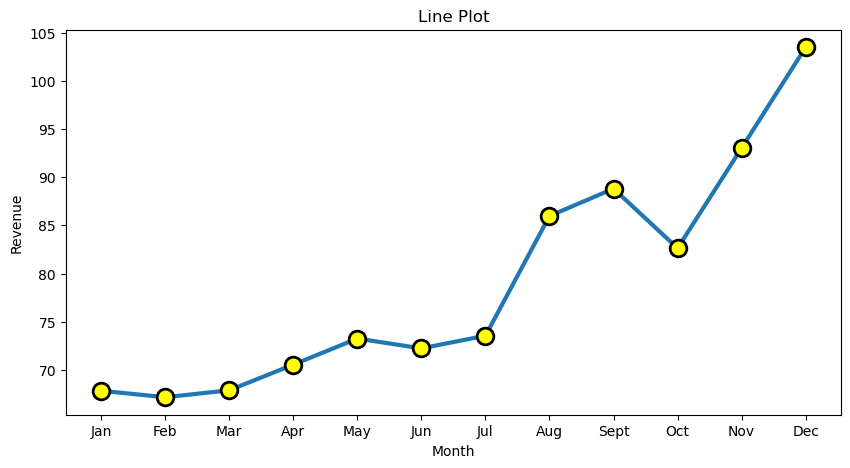

In [16]:
#12)
revenue_lakhs=df25.groupby("month_num")["revenue_lakhs"].sum()
plt.figure(figsize=(10,5))
plt.plot(revenue_lakhs.index,revenue_lakhs.values,marker="o",markersize=12,markerfacecolor="yellow",markeredgecolor="black",markeredgewidth=2,linewidth=3)
plt.xticks(range(1,13),["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sept","Oct","Nov","Dec"])
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Line Plot")
plt.show()


# Part 5

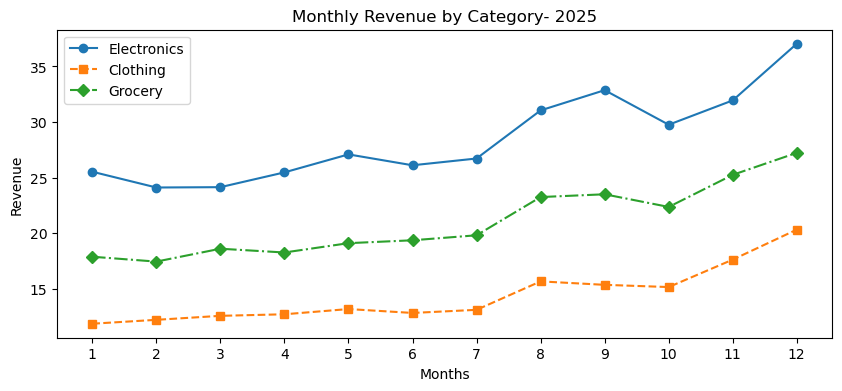

In [17]:
#13)
electronics=df25[df25["category"]=="Electronics"]
clothing=df25[df25["category"]=="Clothing"]
grocery=df25[df25["category"]=="Grocery"]

electronics_revenue=electronics.groupby("month_num")["revenue_lakhs"].sum()
clothing_revenue=clothing.groupby("month_num")["revenue_lakhs"].sum()
grocery_revenue=grocery.groupby("month_num")["revenue_lakhs"].sum()

plt.figure(figsize=(10,4))
plt.plot(electronics_revenue.index,electronics_revenue.values,marker="o",linestyle="-",label="Electronics")
plt.plot(clothing_revenue.index,clothing_revenue.values,marker="s",linestyle="--",label="Clothing")
plt.plot(grocery_revenue.index,grocery_revenue.values,marker="D",linestyle="-.",label="Grocery")
plt.xlabel("Months")
plt.ylabel("Revenue")
plt.xticks(range(1,13))
plt.title("Monthly Revenue by Category- 2025")
plt.legend()
plt.show()

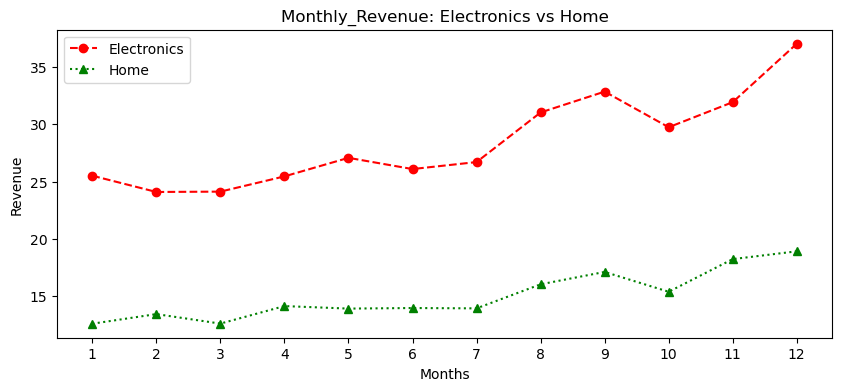

In [18]:
#14)
plt.figure(figsize=(10,4))
electronics=df25[df25["category"]=="Electronics"]
home=df25[df25["category"]=="Home"]

electronics_revenue=electronics.groupby("month_num")["revenue_lakhs"].sum()
home_revenue=home.groupby("month_num")["revenue_lakhs"].sum()

plt.plot(electronics_revenue.index,electronics_revenue.values,"ro--",label="Electronics")
plt.plot(home_revenue.index,home_revenue.values,"g^:",label="Home")
plt.xlabel("Months")
plt.ylabel("Revenue")
plt.title("Monthly_Revenue: Electronics vs Home")
plt.xticks(range(1,13))
plt.legend()
plt.show()

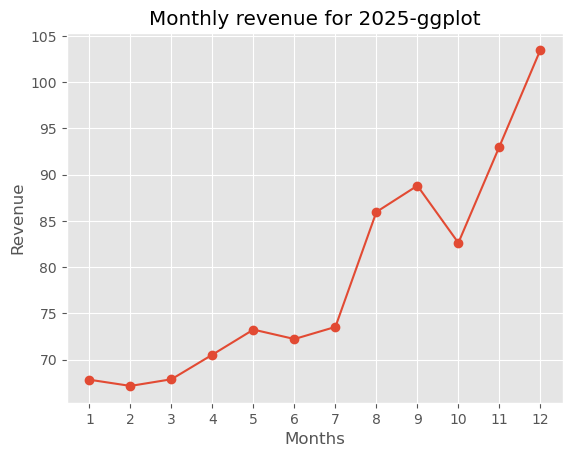

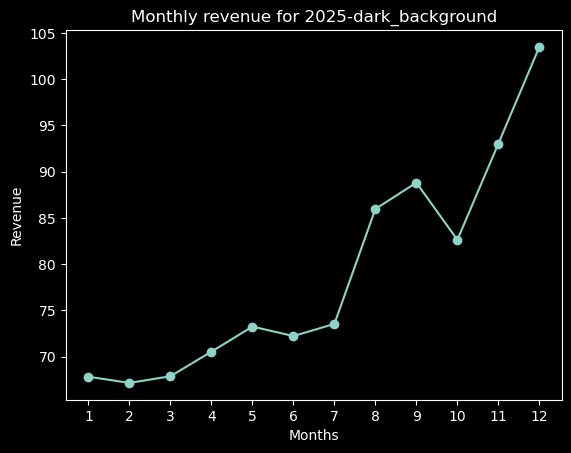

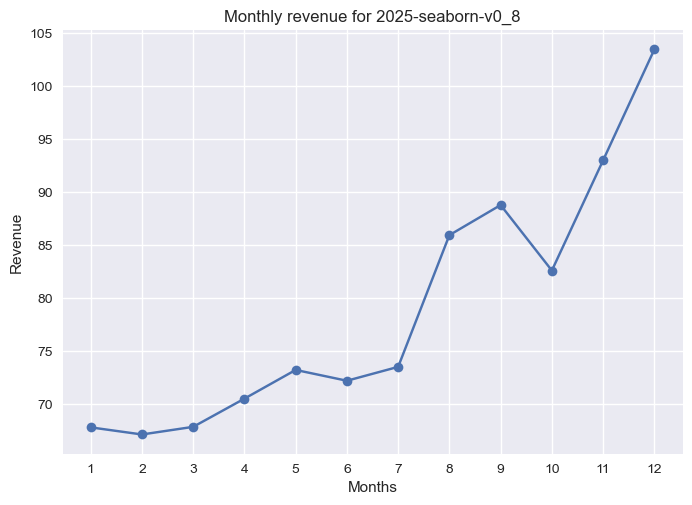

In [19]:
#15)
revenue_lakhs=df25.groupby("month_num")["revenue_lakhs"].sum()
for s in ["ggplot","dark_background","seaborn-v0_8"]:
    plt.style.use(s)
    plt.plot(revenue_lakhs.index,revenue_lakhs.values,marker="o")
    plt.title(f"Monthly revenue for 2025-{s}")
    plt.xlabel("Months")
    plt.ylabel("Revenue")
    plt.xticks(range(1,13))
    plt.show()
    plt.style.use("default")

# Part 6 & 7

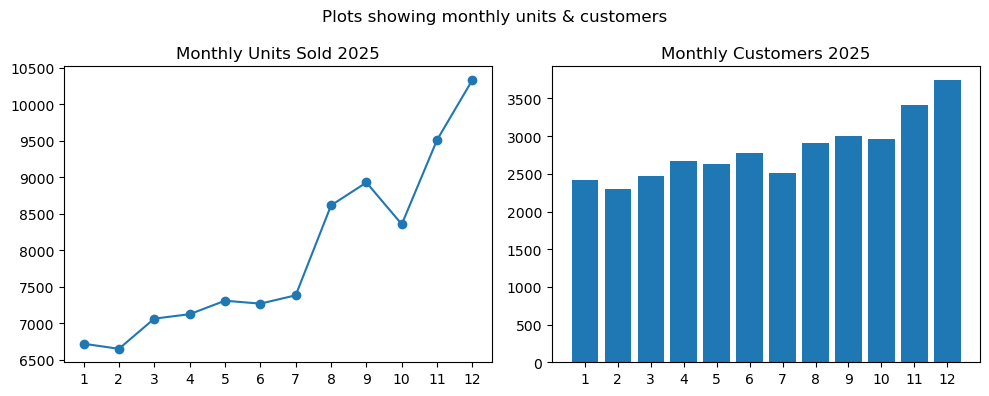

In [21]:
#16)
monthly_units=df25.groupby("month_num")["units_sold"].sum()
monthly_customers=df25.groupby("month_num")["customers"].sum()
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(monthly_units.index,monthly_units.values,marker="o")
plt.xticks(range(1,13))
plt.title("Monthly Units Sold 2025")

plt.subplot(1,2,2)
plt.bar(monthly_customers.index,monthly_customers.values)
plt.xticks(range(1,13))
plt.title("Monthly Customers 2025")

plt.suptitle("Plots showing monthly units & customers")
plt.tight_layout()
plt.show()

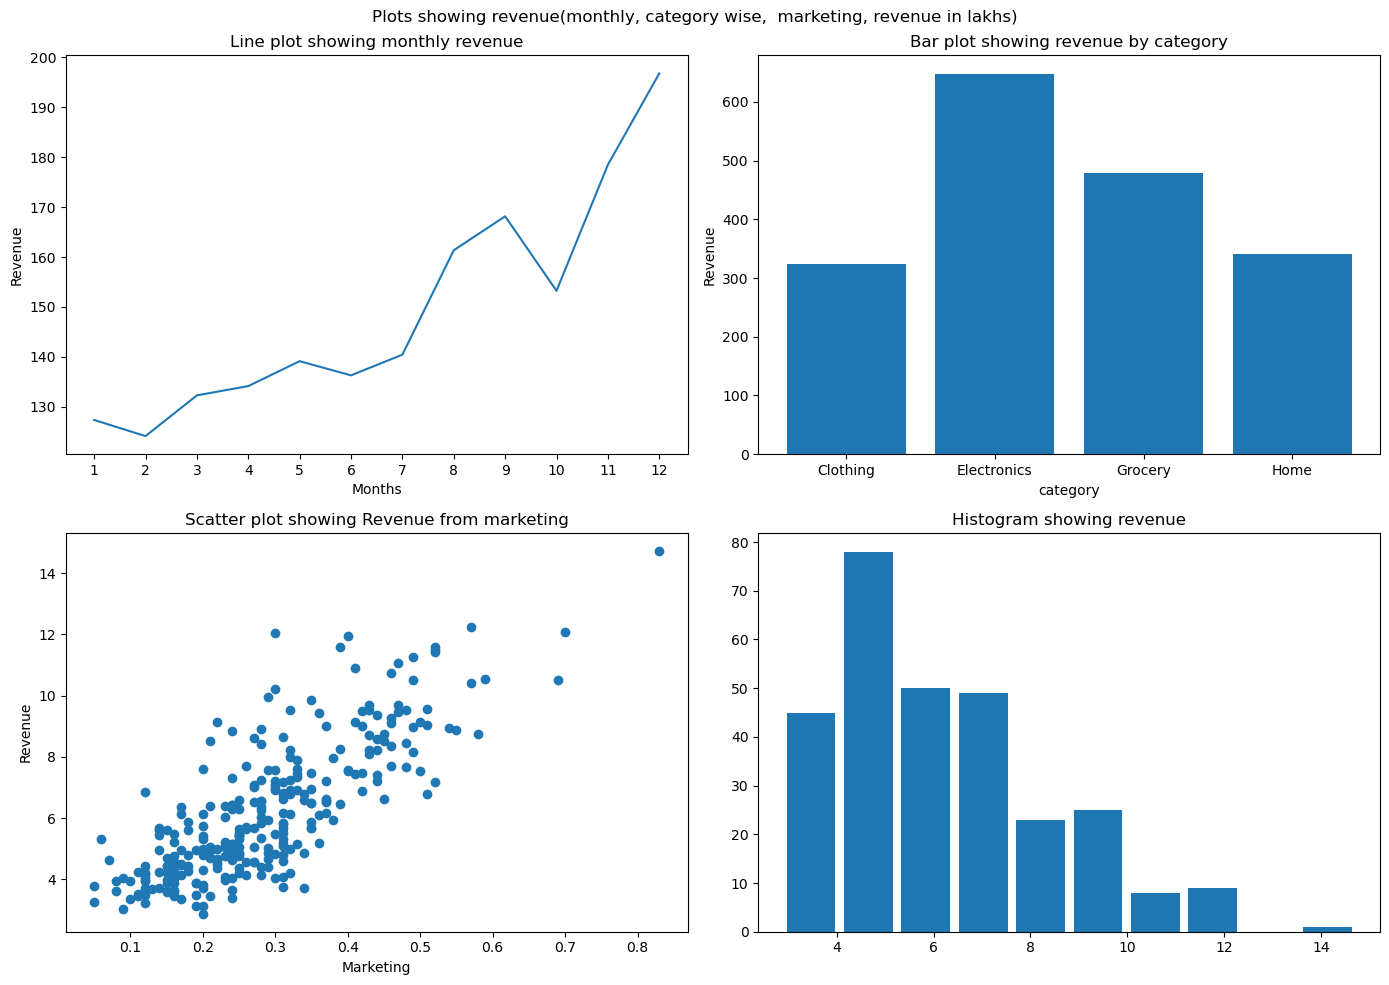

In [22]:
#17)
revenue_lakhs=df.groupby("month_num")["revenue_lakhs"].sum()
category_revenue=df.groupby("category")["revenue_lakhs"].sum()
plt.figure(figsize=(14,10))
plt.subplot(2,2,1)
plt.plot(revenue_lakhs.index,revenue_lakhs.values)
plt.xticks(range(1,13))
plt.title("Line plot showing monthly revenue")
plt.xlabel("Months")
plt.ylabel("Revenue")

plt.subplot(2,2,2)
plt.bar(category_revenue.index,category_revenue.values)
plt.title("Bar plot showing revenue by category")
plt.xlabel("category")
plt.ylabel("Revenue")

plt.subplot(2,2,3)
plt.scatter(df["marketing_spend_lakhs"],df["revenue_lakhs"])
plt.title("Scatter plot showing Revenue from marketing")
plt.xlabel("Marketing")
plt.ylabel("Revenue")

plt.subplot(2,2,4)
plt.hist(df["revenue_lakhs"],rwidth=0.85)
plt.title("Histogram showing revenue")

plt.suptitle("Plots showing revenue(monthly, category wise,  marketing, revenue in lakhs)")
plt.tight_layout()
plt.show()

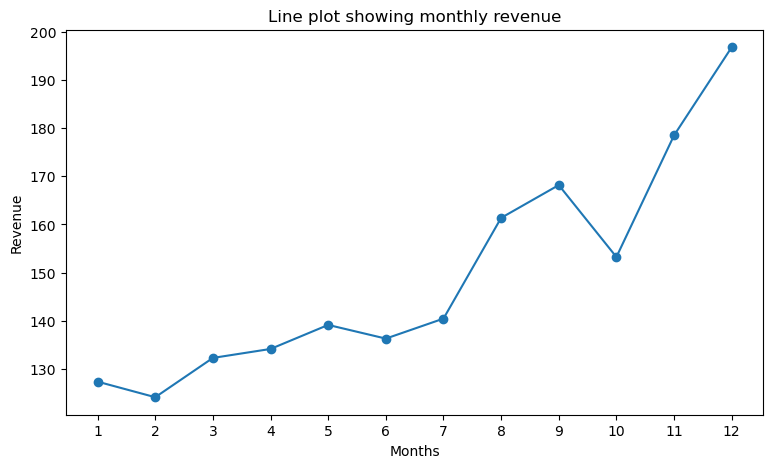

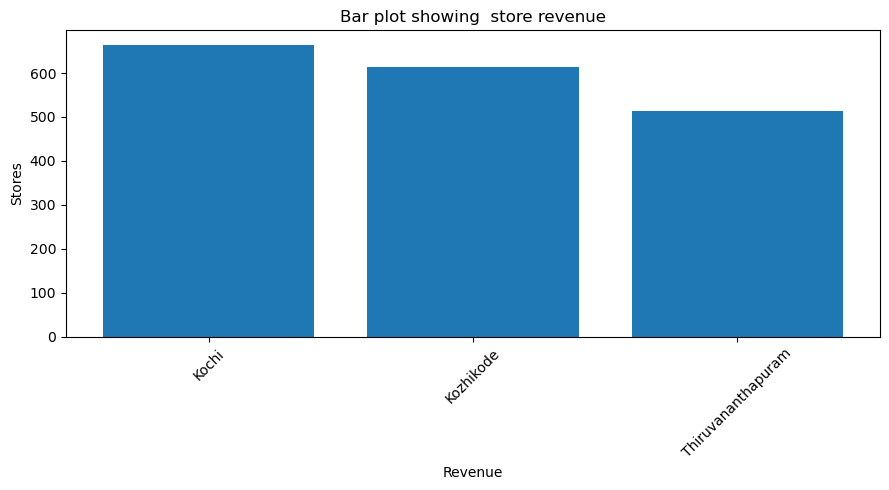

In [23]:
#18)
revenue=df.groupby("month_num")["revenue_lakhs"].sum()
plt.figure(figsize=(9,5))
plt.plot(revenue.index,revenue.values,marker="o")
plt.xticks(range(1,13))
plt.title("Line plot showing monthly revenue")
plt.xlabel("Months")
plt.ylabel("Revenue")

revenue_store=df.groupby("store")["revenue_lakhs"].sum()
plt.figure(figsize=(9,5))
plt.bar(revenue_store.index,revenue_store.values)
plt.xlabel("Revenue")
plt.ylabel("Stores")
plt.title("Bar plot showing  store revenue")
plt.xticks(rotation=45)
plt.tight_layout()


plt.show()


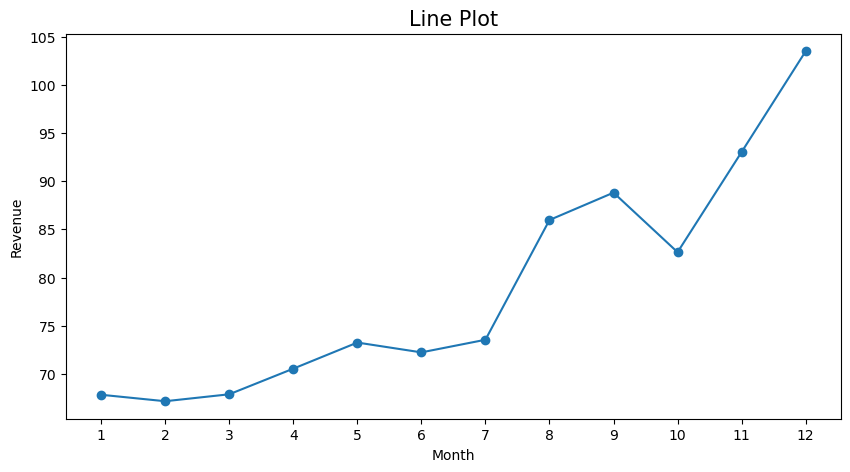

['revenue.pdf', 'revenue.png', 'revenue.svg', 'sales.pdf', 'sales.png', 'sales.svg']


In [ ]:
#19)
import os
os.makedirs("Plots",exist_ok=True)
plt.figure(figsize=(10,5))
revenue_lakhs=df25.groupby("month_num",as_index=False)["revenue_lakhs"].sum()
plt.plot(revenue_lakhs["month_num"],revenue_lakhs["revenue_lakhs"],marker="o")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(1,13))
plt.title("Line Plot",fontsize=15)
plt.savefig("Plots/revenue.png",dpi=300,bbox_inches="tight")
plt.savefig("Plots/revenue.pdf")
plt.savefig("Plots/revenue.svg")
plt.show()
print(os.listdir("Plots")) # if savefig( )is called after show() it might save a blank figure

# Part 8

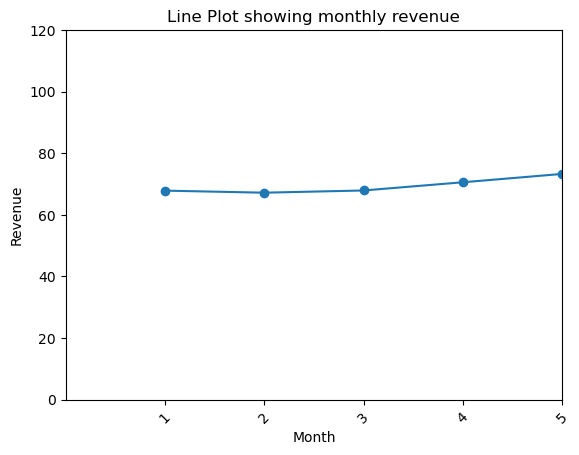

In [86]:
#20)
revenue_lakhs=df25.groupby("month_num",as_index=False)["revenue_lakhs"].sum()
plt.plot(revenue_lakhs["month_num"],revenue_lakhs["revenue_lakhs"],marker="o")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(1,13),rotation=45)
plt.ylim(0,120)
plt.xlim(0,5)
plt.yticks([0,20,40,60,80,100,120])
plt.title("Line Plot showing monthly revenue")
plt.show()

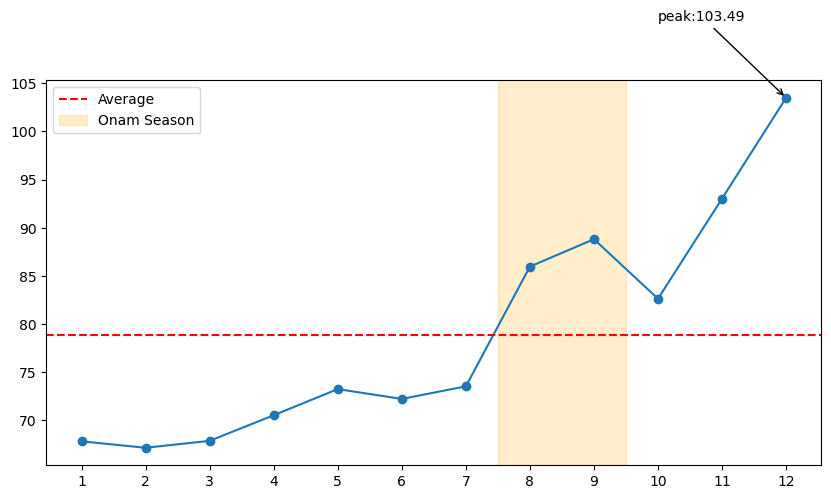

In [29]:
#21,22)
monthly_revenue=df25.groupby("month_num",as_index=False)["revenue_lakhs"].sum()
peak=monthly_revenue.sort_values("revenue_lakhs",ascending=False).iloc[0]
avg=monthly_revenue["revenue_lakhs"].mean()
plt.figure(figsize=(10,5))
plt.plot(monthly_revenue["month_num"],monthly_revenue["revenue_lakhs"],marker="o")
plt.annotate("peak:"+str(round(peak["revenue_lakhs"],2)),
             xy=(peak["month_num"],peak["revenue_lakhs"]),
             xytext=(peak["month_num"]-2,peak["revenue_lakhs"]+8),
             arrowprops={"arrowstyle":"->"})


plt.axhline(avg,color="red",linestyle="--",label="Average")
plt.axvspan(7.5,9.5,color="orange",alpha=0.2,label="Onam Season")
plt.xticks(range(1,13))
plt.legend()
plt.show()

# part 9

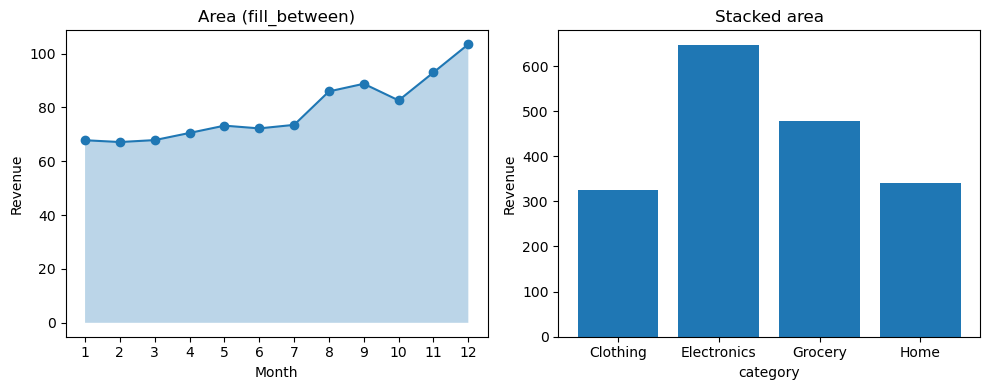

In [87]:
#23)
revenue_lakhs=df25.groupby("month_num",as_index=False)["revenue_lakhs"].sum()
category_revenue=df.groupby("category",as_index=False)["revenue_lakhs"].sum()

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.fill_between(revenue_lakhs["month_num"],revenue_lakhs["revenue_lakhs"],alpha=0.3)
plt.plot(revenue_lakhs["month_num"],revenue_lakhs["revenue_lakhs"],marker="o")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(1,13))
plt.title("Area (fill_between)")

plt.subplot(1,2,2)
plt.bar(category_revenue["category"],category_revenue["revenue_lakhs"])
plt.title("Bar plot showing revenue by category")
plt.xlabel("category")
plt.ylabel("Revenue")
plt.title("Stacked area")
plt.tight_layout()
plt.show()


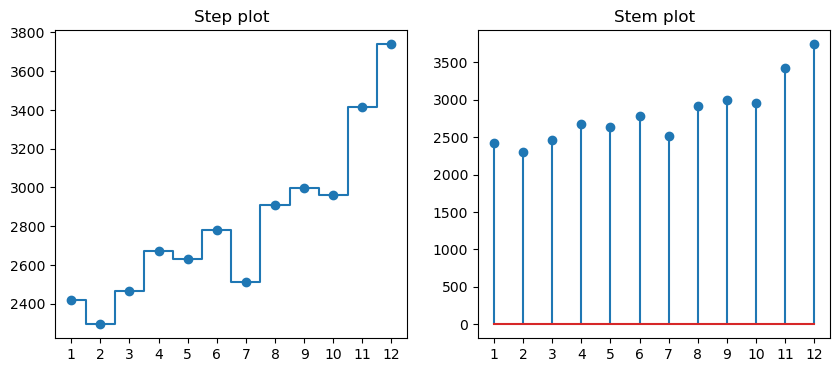

In [30]:
#24)
monthly_customers=df25.groupby("month_num",as_index=False)["customers"].sum()
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.step(monthly_customers["month_num"],monthly_customers["customers"],where="mid",marker="o")
plt.xticks(range(1,13))
plt.title("Step plot")

plt.subplot(1,2,2)
plt.stem(monthly_customers["month_num"],monthly_customers["customers"])
plt.xticks(range(1,13))
plt.title("Stem plot")
plt.show()

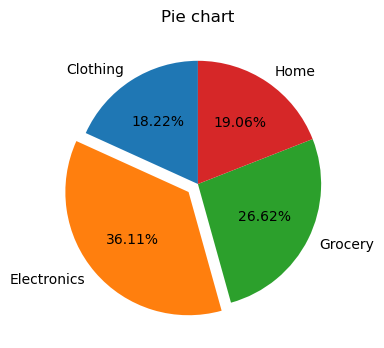

In [102]:
#25)
category_revenue=df25.groupby("category",as_index=False)["revenue_lakhs"].sum()
largest=category_revenue["revenue_lakhs"].values.argmax()
explode=[0,0,0,0]
explode[largest]=0.1
plt.figure(figsize=(10,4))
plt.pie(category_revenue["revenue_lakhs"],labels=category_revenue["category"],autopct="%1.2f%%",explode=explode,startangle=90)
plt.title("Pie chart")
plt.show()

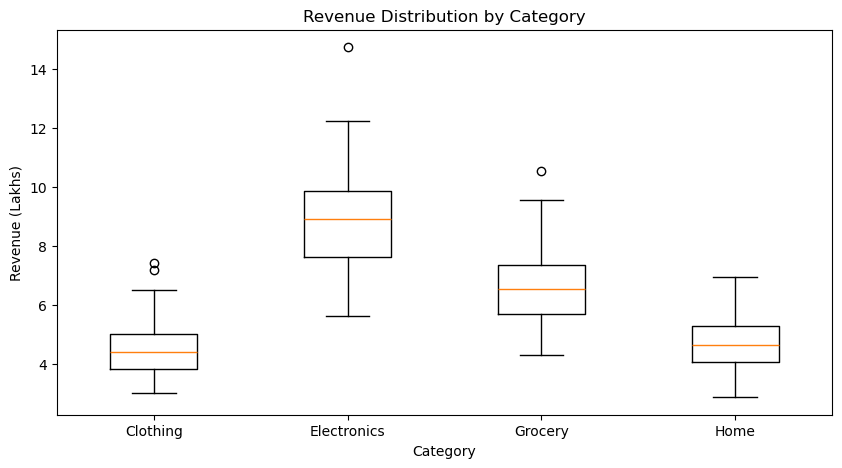

In [34]:
#26)

plt.figure(figsize=(10, 5))

plt.boxplot([
    df[df["category"] == "Clothing"]["revenue_lakhs"],
    df[df["category"] == "Electronics"]["revenue_lakhs"],
    df[df["category"] == "Grocery"]["revenue_lakhs"],
    df[df["category"] == "Home"]["revenue_lakhs"]
],
tick_labels=["Clothing", "Electronics", "Grocery", "Home"])
#df.boxplot(column="revenue_lakhs",by="category")

plt.title("Revenue Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (Lakhs)")

plt.show()


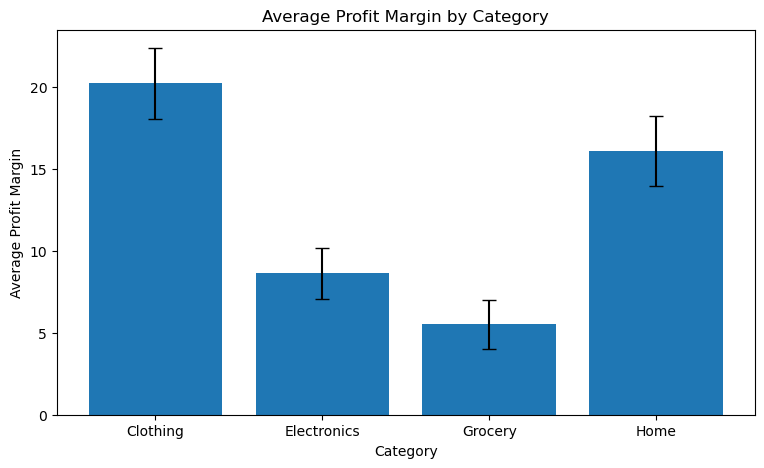

In [105]:
#27)
avg = df.groupby("category")["profit_margin_pct"].mean()
sd = df.groupby("category")["profit_margin_pct"].std()

plt.figure(figsize=(9, 5))
plt.bar(avg.index, avg, yerr=sd, capsize=5)
plt.xlabel("Category")
plt.ylabel("Average Profit Margin")
plt.title("Average Profit Margin by Category")
plt.show()


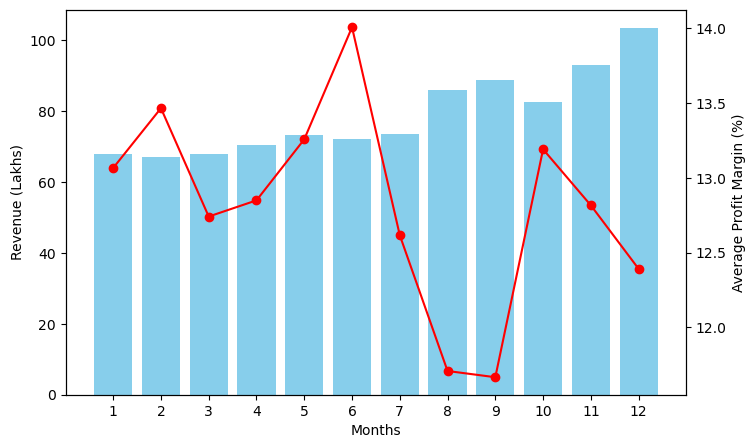

In [111]:
#28)
revenue_lakhs=df25.groupby("month_num",as_index=False)["revenue_lakhs"].sum()
monthly_profit = df25.groupby("month_num", as_index=False)["profit_margin_pct"].mean()
plt.figure(figsize=(8,5))
plt.bar(revenue_lakhs["month_num"], revenue_lakhs["revenue_lakhs"],color="skyblue", label="Revenue")
plt.xticks(range(1,13))
plt.xlabel("Months")
plt.ylabel("Revenue (Lakhs)")

plt.twinx()
plt.plot(monthly_profit["month_num"],monthly_profit["profit_margin_pct"],color="red", marker="o", label="Profit Margin")
plt.ylabel("Average Profit Margin (%)")
plt.show()

# part 10 &12


<Figure size 1000x400 with 0 Axes>

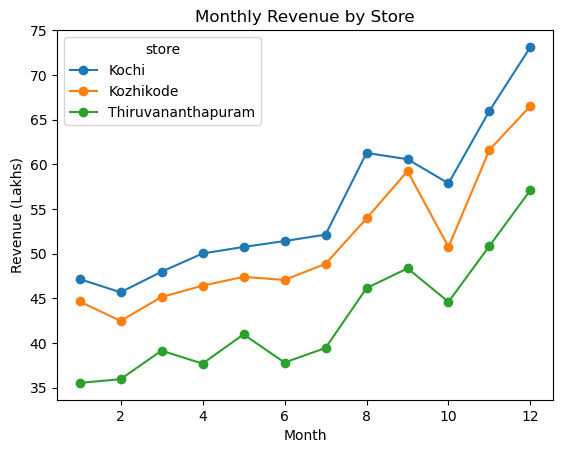

<Figure size 900x500 with 0 Axes>

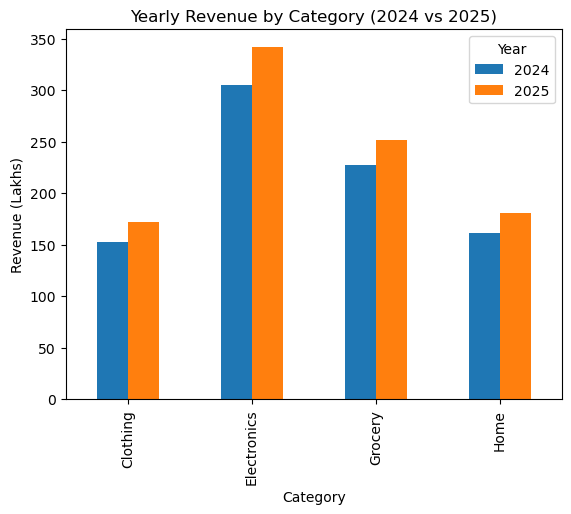

In [117]:
#29)
monthly_store = pd.crosstab(index=df["month_num"],columns=df["store"],values=df["revenue_lakhs"],aggfunc="sum")
plt.figure(figsize=(10,4))
monthly_store.plot(kind="line", marker="o")
plt.title("Monthly Revenue by Store")
plt.xlabel("Month")
plt.ylabel("Revenue (Lakhs)")
plt.show()


#b)
yearly_revenue = pd.crosstab(index=df["category"],columns=df["year"],values=df["revenue_lakhs"],aggfunc="sum")
plt.figure(figsize=(9,5))
yearly_revenue.plot(kind="bar")
plt.title("Yearly Revenue by Category (2024 vs 2025)")
plt.xlabel("Category")
plt.ylabel("Revenue (Lakhs)")
plt.legend(title="Year")

import os
os.makedirs("plots", exist_ok=True)

plt.savefig("plots/yearly.pdf")
plt.show()

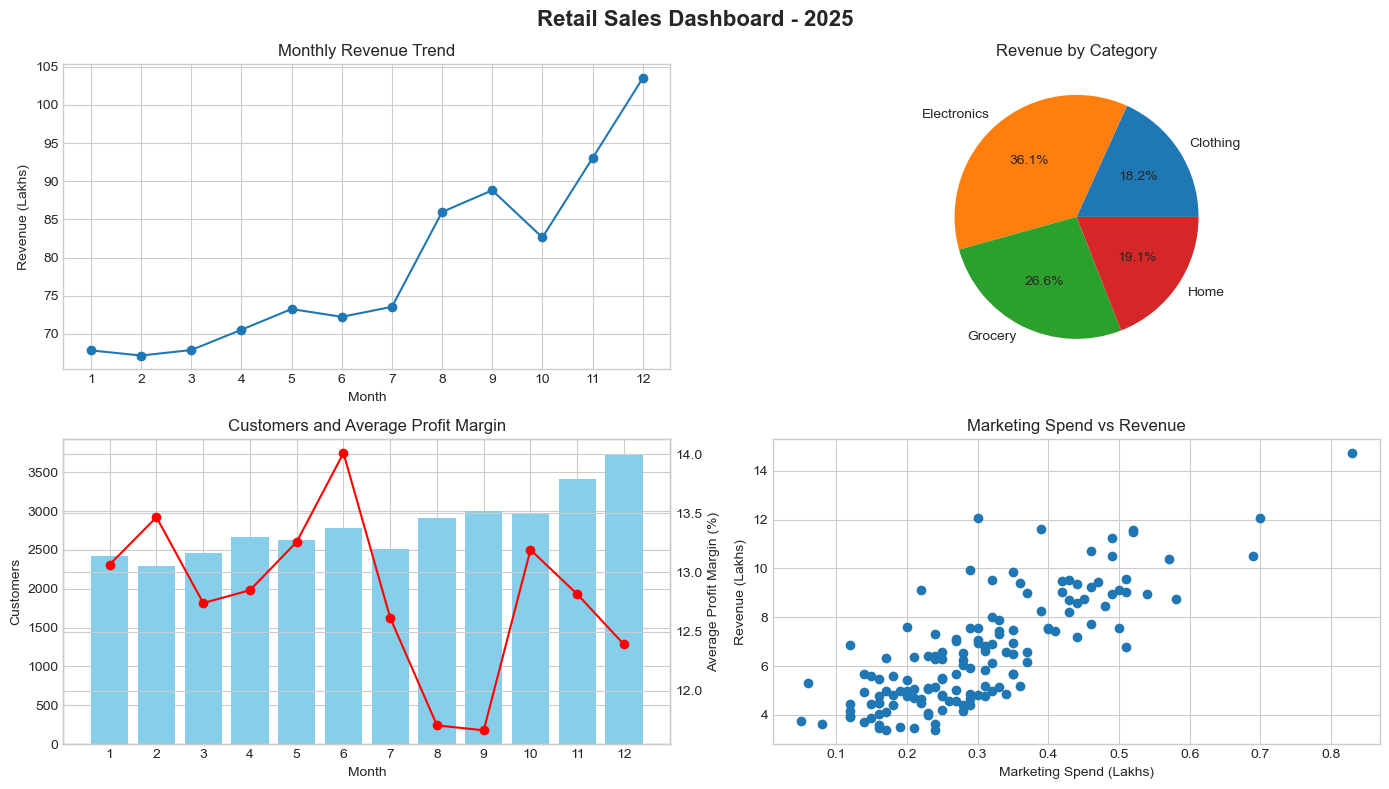

In [122]:
#30)
plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(14, 8))

# 1. Monthly revenue line plot
plt.subplot(2, 2, 1)
monthly = df25.groupby("month_num", as_index=False)["revenue_lakhs"].sum()
plt.plot(monthly["month_num"], monthly["revenue_lakhs"], marker="o")
plt.xticks(range(1,13))
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (Lakhs)")

# 2. Pie chart
plt.subplot(2, 2, 2)
category = df25.groupby("category", as_index=False)["revenue_lakhs"].sum()
plt.pie(category["revenue_lakhs"],labels=category["category"],autopct="%1.1f%%")
plt.title("Revenue by Category")

# 3. Customers bar chart + profit margin line
plt.subplot(2, 2, 3)
monthly_data = df25.groupby("month_num", as_index=False).agg({"customers": "sum","profit_margin_pct": "mean"})
plt.bar(monthly_data["month_num"], monthly_data["customers"],color="skyblue", label="Customers")
plt.xticks(range(1,13))
plt.xlabel("Month")
plt.ylabel("Customers")
plt.title("Customers and Average Profit Margin")

plt.twinx()
plt.plot(monthly_data["month_num"], monthly_data["profit_margin_pct"],color="red", marker="o", label="Average Margin")
plt.ylabel("Average Profit Margin (%)")

# 4. Scatter plot
plt.subplot(2, 2, 4)
plt.scatter(df25["marketing_spend_lakhs"],df25["revenue_lakhs"])
plt.title("Marketing Spend vs Revenue")
plt.xlabel("Marketing Spend (Lakhs)")
plt.ylabel("Revenue (Lakhs)")

plt.suptitle("Retail Sales Dashboard - 2025",fontsize=16, fontweight="bold")
plt.tight_layout()

os.makedirs("plots", exist_ok=True)
plt.savefig("plots/dashboard.png", dpi=200, bbox_inches="tight")
plt.savefig("Plots/dashboard.pdf")

plt.show()
plt.style.use("default")
